# Week 3 – Hospital Operations: Statistical Investigation & Insight Discovery

## Research question
**How do total claim costs vary across encounter classes, and is encounter duration associated with total claim cost?**

This notebook focuses on exploratory data analysis, two hypothesis tests, interpretation, limitations and recommendations.


# 1. Business problem and research question

The hospital wants to understand how recorded claim costs vary across types of encounters and whether longer encounters tend to have higher claim costs.

**Why it matters:** Understanding cost patterns can help hospital operations teams identify encounter classes that may need further financial review.

**Intended users:** Hospital operations and finance teams.

**Decision supported:** Where to focus further investigation of encounter costs.

**Evidence limitation:** The data is historical and observational. It can show patterns and associations, not prove that encounter class or duration causes higher costs.


In [1]:
import os, csv, json, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42                                    # one seed, so every random step is repeatable
rng = np.random.default_rng(SEED)
DATA, FIG, TAB, REP = "data", "outputs/figures", "outputs/tables", "reports"
for folder in (FIG, TAB, REP):
    os.makedirs(folder, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREY = "#1f6f8b", "#e07b39", "#8a8f94"
RESULTS = {}                                 # key numbers collected here for the report and slides

def save_fig(name):
    """Tidy, save into outputs/figures, and show."""
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

def show_md(text):
    display(Markdown(text))

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def money(x):
    return f"${x:,.0f}"                      # costs are assumed to be US dollars (the dictionary does not state a currency)

dq_log = []                                  # data-quality log: one row per check
def log_dq(check, table, finding, meaning, action):
    dq_log.append({"check": check, "table": table, "finding": finding, "what_it_means": meaning, "action_taken": action})

---
# 2. Inspect the datasets
## 2.1 Load the files
Only the columns needed are loaded from `patients.csv` (the `Id`), and only the **column names** are read for the rest, to document its structure.

C:\Users\maseglo.com\Documents\Data Science\Analystlab Africa\Week 3\Week3_Hospital_DataScience


['.gitignore', '.ipynb_checkpoints', 'data', 'Hospital Operations Cost & Encounter Analysis.pdf', 'outputs', 'README.md', 'reports', 'requirements.txt', 'Week3_Hospital_Analysis.ipynb', 'Week3_Hospital_Analysis_Data_Science_Simplified.ipynb']


In [4]:
enc = pd.read_csv(f"{DATA}/encounters.csv")
proc = pd.read_csv(f"{DATA}/procedures.csv")
payers = pd.read_csv(f"{DATA}/payers.csv")
orgs = pd.read_csv(f"{DATA}/organizations.csv", usecols=["Id", "NAME"])
patient_ids = pd.read_csv(f"{DATA}/patients.csv", usecols=["Id"])             # privacy: ID only
patient_columns = list(pd.read_csv(f"{DATA}/patients.csv", nrows=0).columns)   # names of columns only
dictionary = pd.read_csv(f"{DATA}/data_dictionary.csv")

overview = pd.DataFrame({
    "table": ["encounters", "procedures", "payers", "organizations", "patients", "data_dictionary"],
    "rows": [len(enc), len(proc), len(payers), len(orgs), len(patient_ids), len(dictionary)],
    "columns": [enc.shape[1], proc.shape[1], payers.shape[1], 2, len(patient_columns), dictionary.shape[1]],
    "used_for": ["PRIMARY analysis table", "cost-reconciliation check and context", "payer names", "confirm single organisation", "key check only (no personal data loaded)", "field definitions"]})
display(overview)
overview.to_csv(f"{TAB}/table_overview.csv", index=False)
print("Encounter columns:", list(enc.columns))

,table,rows,columns,used_for
0,encounters,27891,14,PRIMARY analysis table
1,procedures,47701,9,cost-reconciliation check and context
2,payers,10,7,payer names
3,organizations,1,2,confirm single organisation
4,patients,974,20,key check only (no personal data loaded)
5,data_dictionary,65,3,field definitions


Encounter columns: ['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']


## 2.2 Do the fields in the data dictionary exist in the files?
The brief warns that not every dictionary field is necessarily present. We compare them properly (ignoring upper/lower case and spaces).

In [5]:
def clean_name(s):
    return str(s).lower().replace(" ", "").replace("_", "")

file_columns = {"encounters": list(enc.columns), "procedures": list(proc.columns), "payers": list(payers.columns),
                "organizations": list(pd.read_csv(f"{DATA}/organizations.csv", nrows=0).columns), "patients": patient_columns}
dict_fields = dictionary.dropna(subset=["Field"])                                # rows without a field are section headings
rows = []
for table, cols in file_columns.items():
    in_dict = {clean_name(f) for f in dict_fields.loc[dict_fields["Table"] == table, "Field"]}
    in_file = {clean_name(c) for c in cols}
    for f in sorted(in_dict - in_file): rows.append((table, f, "in dictionary but NOT in the file"))
    for f in sorted(in_file - in_dict): rows.append((table, f, "in the file but NOT in the dictionary"))
dict_check = pd.DataFrame(rows, columns=["table", "field", "issue"])
display(dict_check if len(dict_check) else pd.DataFrame({"result": ["every field matches"]}))
print("Fields I need are all present in encounters.csv:", all(c in enc.columns for c in ["ENCOUNTERCLASS", "TOTAL_CLAIM_COST", "START", "STOP", "PAYER_COVERAGE", "BASE_ENCOUNTER_COST"]))
log_dq("Dictionary vs files", "all", f"{len(dict_check)} field mismatches (e.g. {', '.join(dict_check['field'].head(3))})", "The dictionary describes fields that the supplied file does not contain", "Fields used in this analysis all exist in encounters.csv; the mismatches do not affect the analysis")

,table,field,issue
0,patients,fipscountycode,in dictionary but NOT in the file
1,patients,middle,in dictionary but NOT in the file


Fields I need are all present in encounters.csv: True


## 2.3 Relationships between tables
Keys must match before tables can be linked. We check the share of records whose key exists in the parent table.

In [6]:
keys = pd.DataFrame([
    ("encounters.PATIENT -> patients.Id", enc["PATIENT"].isin(patient_ids["Id"]).mean()),
    ("encounters.PAYER -> payers.Id", enc["PAYER"].isin(payers["Id"]).mean()),
    ("encounters.ORGANIZATION -> organizations.Id", enc["ORGANIZATION"].isin(orgs["Id"]).mean()),
    ("procedures.ENCOUNTER -> encounters.Id", proc["ENCOUNTER"].isin(enc["Id"]).mean()),
    ("procedures.PATIENT -> patients.Id", proc["PATIENT"].isin(patient_ids["Id"]).mean())], columns=["relationship", "share_of_records_matching"])
keys["share_of_records_matching"] = (keys["share_of_records_matching"] * 100).round(2).astype(str) + "%"
display(keys)
print("Organisations in the data:", orgs["NAME"].tolist(), "| payers:", len(payers))
log_dq("Key integrity", "encounters, procedures", "All foreign keys match their parent tables (100%)", "Tables can be joined safely", "No records dropped by joins")
log_dq("Single organisation", "organizations", f"Only {len(orgs)} organisation ({orgs['NAME'].iloc[0]})", "Findings cannot be generalised beyond this one hospital", "Stated as a limitation")

,relationship,share_of_records_matching
0,encounters.PATIENT -> patients.Id,100.0%
1,encounters.PAYER -> payers.Id,100.0%
2,encounters.ORGANIZATION -> organizations.Id,100.0%
3,procedures.ENCOUNTER -> encounters.Id,100.0%
4,procedures.PATIENT -> patients.Id,100.0%


Organisations in the data: ['MASSACHUSETTS GENERAL HOSPITAL'] | payers: 10


## 2.4 Duplicates, missing values and data types
**No automatic clean-up:** duplicates and gaps are first understood, then handled.

In [7]:
dup_rows = int(enc.duplicated().sum()); dup_ids = int(enc["Id"].duplicated().sum())
dup_same = int(enc.duplicated(["PATIENT", "START", "ENCOUNTERCLASS"]).sum())
print(f"Fully duplicated encounter rows: {dup_rows} | repeated encounter Id: {dup_ids} | same patient, start time and class: {dup_same}")
print(f"Fully duplicated procedure rows: {int(proc.duplicated().sum())}")

miss = pd.DataFrame({"encounters_missing": enc.isna().sum(), "encounters_%": (enc.isna().mean() * 100).round(1)})
miss = miss[miss["encounters_missing"] > 0]
miss_p = pd.DataFrame({"procedures_missing": proc.isna().sum(), "procedures_%": (proc.isna().mean() * 100).round(1)})
display(miss); display(miss_p[miss_p["procedures_missing"] > 0])
print("Data types (encounters):"); print(enc.dtypes.to_string())

Fully duplicated encounter rows: 0 | repeated encounter Id: 0 | same patient, start time and class: 27
Fully duplicated procedure rows: 0


,encounters_missing,encounters_%
REASONCODE,19541,70.1
REASONDESCRIPTION,19541,70.1


,procedures_missing,procedures_%
REASONCODE,36945,77.5
REASONDESCRIPTION,36945,77.5


Data types (encounters):
Id                      object
START                   object
STOP                    object
PATIENT                 object
ORGANIZATION            object
PAYER                   object
ENCOUNTERCLASS          object
CODE                     int64
DESCRIPTION             object
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
PAYER_COVERAGE         float64
REASONCODE             float64
REASONDESCRIPTION       object


**Reading this.** Only the *reason* columns have gaps. A blank reason simply means that no specific condition was recorded for that encounter (it is not a data-entry error), so those blanks are **left as they are** and the columns are not used in the analysis. There are no duplicated encounter IDs. The `START` and `STOP` columns are stored as text and must be converted to dates.

In [8]:
log_dq("Duplicates", "encounters", f"{dup_rows} fully duplicated rows, {dup_ids} repeated encounter Ids", "No duplicate records", "Nothing removed")
log_dq("Same patient/time/class", "encounters", f"{dup_same} encounters share patient, start time and class with another", "Possibly separate services at one visit rather than errors", "Kept (not deleted); noted as a limitation")
log_dq("Missing values", "encounters", f"REASONCODE/REASONDESCRIPTION blank in {enc['REASONCODE'].isna().mean() * 100:.0f}% of encounters; no other gaps", "Blank means no reason recorded, not a data error", "Left blank; columns not used")
log_dq("Missing values", "procedures", f"REASONCODE/REASONDESCRIPTION blank in {proc['REASONCODE'].isna().mean() * 100:.0f}% of procedures", "Same meaning as above", "Left blank; columns not used")
log_dq("Data types", "encounters", "START and STOP stored as text", "Needed as dates to calculate duration", "Converted to datetime (UTC) in Section 2.5")
log_dq("Privacy", "patients", "patients.csv holds names and addresses", "Personal details must not appear in outputs or a public repository", "Only the Id column is loaded; patients.csv is excluded from Git")

## 2.5 Dates, durations, costs and payer coverage

In [9]:
enc["START"] = pd.to_datetime(enc["START"], utc=True)          # text -> date and time
enc["STOP"] = pd.to_datetime(enc["STOP"], utc=True)
enc["duration_hours"] = (enc["STOP"] - enc["START"]).dt.total_seconds() / 3600     # duration in hours
enc["year"] = enc["START"].dt.year

print("Dates parsed without error: START missing =", int(enc["START"].isna().sum()), "| STOP missing =", int(enc["STOP"].isna().sum()))
print("Encounter dates:", enc["START"].min().date(), "to", enc["START"].max().date())
print("Negative durations:", int((enc["duration_hours"] < 0).sum()), "| zero durations:", int((enc["duration_hours"] == 0).sum()))
dur_by_class = enc.groupby("ENCOUNTERCLASS")["duration_hours"].agg(["count", "min", "median", "max", pd.Series.nunique]).rename(columns={"nunique": "different_values"})
display(dur_by_class.round(2))

Dates parsed without error: START missing = 0 | STOP missing = 0
Encounter dates: 2011-01-02 to 2022-02-05
Negative durations: 0 | zero durations: 0


,count,min,median,max,different_values
ENCOUNTERCLASS,,,,,
ambulatory,12537,0.25,0.25,44930.00,1379
emergency,2322,1.00,1.00,589.00,38
inpatient,1135,24.00,24.00,8250.00,59
outpatient,6300,0.25,0.25,10704.00,445
urgentcare,3666,0.25,0.25,0.25,1
wellness,1931,0.25,0.25,0.25,1


**Observations about duration (important for H2):**
* Duration is **fixed by encounter class** for some classes (the number of *different* duration values is 1 for them), so duration carries little independent information there.
* Every inpatient stay lasts **at least 24 hours**, so "longer than 24 hours" means something different from "24 hours or more" (counted separately below).
* A few encounters last **more than a year**, which is unusual and is treated as extreme rather than deleted.

In [10]:
n_gt24 = int((enc["duration_hours"] * 3600 > 86400).sum()); n_ge24 = int((enc["duration_hours"] * 3600 >= 86400).sum())
n_gt1y = int((enc["duration_hours"] > 24 * 365).sum())
print(f"Longer than 24 hours: {n_gt24:,} ({n_gt24 / len(enc):.2%}) | 24 hours or more: {n_ge24:,} ({n_ge24 / len(enc):.2%}) | longer than one year: {n_gt1y} (max {enc['duration_hours'].max():,.0f} hours = {enc['duration_hours'].max() / 24 / 365:.1f} years)")

# costs
n_zero_claim = int((enc["TOTAL_CLAIM_COST"] == 0).sum())
zero_by_class = enc.loc[enc["TOTAL_CLAIM_COST"] == 0, "ENCOUNTERCLASS"].value_counts().to_dict()
print(f"Zero total claim cost: {n_zero_claim} encounters {zero_by_class}; base cost on those: {enc.loc[enc['TOTAL_CLAIM_COST'] == 0, 'BASE_ENCOUNTER_COST'].min():.0f} to {enc.loc[enc['TOTAL_CLAIM_COST'] == 0, 'BASE_ENCOUNTER_COST'].max():.0f}")
print("Total claim cost summary:"); print(enc["TOTAL_CLAIM_COST"].describe().round(1).to_string())
print(f"Mean {enc['TOTAL_CLAIM_COST'].mean():,.0f} is far above the median {enc['TOTAL_CLAIM_COST'].median():,.0f}: costs are heavily right-skewed.")

# partial years
by_year = enc.groupby("year").size()
print("Encounters per year:", by_year.to_dict())

Longer than 24 hours: 75 (0.27%) | 24 hours or more: 1,152 (4.13%) | longer than one year: 4 (max 44,930 hours = 5.1 years)
Zero total claim cost: 89 encounters {'wellness': 51, 'inpatient': 28, 'emergency': 6, 'ambulatory': 4}; base cost on those: 86 to 146
Total claim cost summary:
count     27891.0
mean       3639.7
std        9205.6
min           0.0
25%         142.6
50%         278.6
75%        1412.5
max      641882.7
Mean 3,640 is far above the median 279: costs are heavily right-skewed.
Encounters per year: {2011: 1336, 2012: 2106, 2013: 2495, 2014: 3885, 2015: 2469, 2016: 2451, 2017: 2360, 2018: 2292, 2019: 2228, 2020: 2519, 2021: 3530, 2022: 220}


Costs are **extremely skewed** (a few very expensive encounters), so averages are easily misleading and the **median** is a better "typical" figure. The first and last years are partial: the data begins in early January 2011 and ends in early February 2022.

In [11]:
# payer coverage
enc["payer_name"] = enc["PAYER"].map(payers.set_index("Id")["NAME"])
enc["zero_coverage"] = enc["PAYER_COVERAGE"] == 0
enc["uninsured"] = enc["payer_name"] == "NO_INSURANCE"
print(f"Encounters with zero recorded payer coverage: {enc['zero_coverage'].sum():,} ({enc['zero_coverage'].mean():.1%})")
print(f"  of which recorded payer is NO_INSURANCE: {(enc['zero_coverage'] & enc['uninsured']).sum():,}")
print(f"  of which a named insurer is recorded but coverage is still zero: {(enc['zero_coverage'] & ~enc['uninsured']).sum():,} ({(enc['zero_coverage'] & ~enc['uninsured']).mean():.1%} of all encounters)")
payer_tbl = enc.groupby("payer_name").agg(encounters=("Id", "count"), zero_coverage_share=("zero_coverage", "mean"), mean_claim=("TOTAL_CLAIM_COST", "mean")).sort_values("encounters", ascending=False)
display(payer_tbl.round(3))
print(f"Coverage recorded as a share of total claim cost, overall: {enc['PAYER_COVERAGE'].sum() / enc['TOTAL_CLAIM_COST'].sum():.1%}")

Encounters with zero recorded payer coverage: 13,586 (48.7%)
  of which recorded payer is NO_INSURANCE: 8,807
  of which a named insurer is recorded but coverage is still zero: 4,779 (17.1% of all encounters)


,encounters,zero_coverage_share,mean_claim
payer_name,,,
Medicare,11371,0.005,2167.552
NO_INSURANCE,8807,1.000,5593.197
Medicaid,1443,0.003,6205.219
Humana,1084,0.958,3269.300
Aetna,936,0.959,2767.047
Blue Cross Blue Shield,925,0.363,3245.585
Dual Eligible,912,0.139,1696.191
UnitedHealthcare,900,0.911,2848.342
Cigna Health,809,0.977,2996.951


Coverage recorded as a share of total claim cost, overall: 30.6%


**Reading this.** Zero coverage is **ambiguous**. For `NO_INSURANCE` it plausibly means "no insurer paid". But many encounters list a *named private insurer* and still record zero coverage, so zero cannot safely be read as "uninsured". Coverage is therefore treated as a *recorded amount*, not as proof of insurance status.

In [12]:
# do cost fields add up? (check whether the claim can be broken into base cost + procedures)
proc_sum = proc.groupby("ENCOUNTER")["BASE_COST"].agg(n_procedures="count", procedure_cost="sum")
enc = enc.merge(proc_sum, left_on="Id", right_index=True, how="left", validate="1:1")
enc[["n_procedures", "procedure_cost"]] = enc[["n_procedures", "procedure_cost"]].fillna(0)
diff = enc["TOTAL_CLAIM_COST"] - enc["BASE_ENCOUNTER_COST"] - enc["procedure_cost"]
share_exact = (diff.abs() < 0.01).mean()
proc_vs_claim = enc["procedure_cost"].sum() / enc["TOTAL_CLAIM_COST"].sum()
print(f"Claim = base cost + procedure costs (within 1 cent) for only {share_exact:.0%} of encounters")
print(f"Sum of all procedure base costs = {proc_vs_claim:.0%} of the sum of all total claim costs")
print(f"Encounters with at least one recorded procedure: {(enc['n_procedures'] > 0).mean():.0%}")
log_dq("Cost reconciliation", "encounters, procedures", f"Total claim = base + procedure costs for only {share_exact:.0%} of encounters; procedure costs sum to {proc_vs_claim:.0%} of total claims", "Cost fields are not simple components of each other (other items such as medications are not in the pack)", "Total claim cost is analysed as recorded; it is not broken down into parts")
log_dq("Dates", "encounters", f"All dates parse; {int((enc['duration_hours'] < 0).sum())} negative durations; {n_gt1y} encounters last > 1 year; first/last years are partial", "Extreme durations are unusual but not impossible for long-running care episodes", "Kept and flagged; sensitivity checks in Section 6")
log_dq("Duration structure", "encounters", "Duration is a single fixed value for some classes; every inpatient stay is >= 24 h", "Duration has limited independent information; '>24 hours' vs '>= 24 hours' differ", "Both definitions reported; H2 also tested within each class")
log_dq("Zero claim cost", "encounters", f"{n_zero_claim} encounters have total claim cost = 0 although base cost is positive", "Claim total is lower than its own base cost, which is inconsistent", "Kept; excluded only from log-scale charts; flagged")
log_dq("Payer coverage", "encounters", f"{enc['zero_coverage'].mean():.0%} of encounters show zero coverage, including {(enc['zero_coverage'] & ~enc['uninsured']).sum():,} with a named insurer", "Zero coverage is ambiguous (not-recorded vs not-covered)", "Reported as 'recorded coverage'; never read as uninsured")
log_dq("Repeated records", "encounters", f"{enc['PATIENT'].nunique()} patients; median {enc.groupby('PATIENT').size().median():.0f} encounters each; maximum {enc.groupby('PATIENT').size().max():,}", "Encounters from the same patient are not independent", "Robustness test using one encounter per patient (Section 6)")

Claim = base cost + procedure costs (within 1 cent) for only 30% of encounters
Sum of all procedure base costs = 104% of the sum of all total claim costs
Encounters with at least one recorded procedure: 53%


## 2.6 Data-quality summary (deliverable)

In [13]:
dq_df = pd.DataFrame(dq_log)
with pd.option_context("display.max_colwidth", 110):
    display(dq_df)
dq_df.to_csv(f"{TAB}/data_quality_summary.csv", index=False)
RESULTS["data_quality_checks"] = len(dq_df)

with open(f"{REP}/Data_Quality_Summary.md", "w", encoding="utf-8") as fh:
    fh.write("# Data-Quality Summary: Hospital Dataset (Week 3, Track B)\n\n")
    fh.write("Generated by the analysis notebook. Costs are assumed to be US dollars; the data follows the Synthea synthetic-patient format.\n\n")
    fh.write("## Tables used\n\n| Table | Rows | Columns | Used for |\n|---|---|---|---|\n")
    for _, r in overview.iterrows(): fh.write(f"| {r['table']} | {r['rows']:,} | {r['columns']} | {r['used_for']} |\n")
    fh.write("\n## Checks, findings and decisions\n\n| Check | Table | Finding | What it means | Action taken |\n|---|---|---|---|---|\n")
    for _, r in dq_df.iterrows(): fh.write(f"| {r['check']} | {r['table']} | {r['finding']} | {r['what_it_means']} | {r['action_taken']} |\n")
    fh.write("\n**Principle applied:** no row was deleted and no missing value was filled. Rows with unusual values are flagged and tested for their influence instead.\n")
print("Saved: outputs/tables/data_quality_summary.csv and reports/Data_Quality_Summary.md")

,check,table,finding,what_it_means,action_taken
0,Dictionary vs files,all,"2 field mismatches (e.g. fipscountycode, middle)",The dictionary describes fields that the supplied file does not contain,Fields used in this analysis all exist in encounters.csv; the mismatches do not affect the analysis
1,Key integrity,"encounters, procedures",All foreign keys match their parent tables (100%),Tables can be joined safely,No records dropped by joins
2,Single organisation,organizations,Only 1 organisation (MASSACHUSETTS GENERAL HOSPITAL),Findings cannot be generalised beyond this one hospital,Stated as a limitation
3,Duplicates,encounters,"0 fully duplicated rows, 0 repeated encounter Ids",No duplicate records,Nothing removed
4,Same patient/time/class,encounters,"27 encounters share patient, start time and class with another",Possibly separate services at one visit rather than errors,Kept (not deleted); noted as a limitation
5,Missing values,encounters,REASONCODE/REASONDESCRIPTION blank in 70% of encounters; no other gaps,"Blank means no reason recorded, not a data error",Left blank; columns not used
6,Missing values,procedures,REASONCODE/REASONDESCRIPTION blank in 77% of procedures,Same meaning as above,Left blank; columns not used
7,Data types,encounters,START and STOP stored as text,Needed as dates to calculate duration,Converted to datetime (UTC) in Section 2.5
8,Privacy,patients,patients.csv holds names and addresses,Personal details must not appear in outputs or a public repository,Only the Id column is loaded; patients.csv is excluded from Git
9,Cost reconciliation,"encounters, procedures",Total claim = base + procedure costs for only 30% of encounters; procedure costs sum to 104% of total claims,Cost fields are not simple components of each other (other items such as medications are not in the pack),Total claim cost is analysed as recorded; it is not broken down into parts


Saved: outputs/tables/data_quality_summary.csv and reports/Data_Quality_Summary.md


---
# 3. Prepare the analysis dataset
All 27,891 encounters are kept. New columns are added; nothing is dropped.

In [14]:
n_before = len(enc)
enc["zero_cost_flag"] = enc["TOTAL_CLAIM_COST"] == 0
enc["extreme_duration_flag"] = enc["duration_hours"] > 24 * 365
enc["log10_cost"] = np.log10(enc["TOTAL_CLAIM_COST"].where(enc["TOTAL_CLAIM_COST"] > 0))        # log scale for charts only (zero cost cannot be logged)
class_order = enc["ENCOUNTERCLASS"].value_counts().index.tolist()
assert len(enc) == n_before == 27891, "rows changed during preparation"
print("Rows before and after preparation:", n_before, len(enc), "(unchanged)")
print("Encounter classes (largest first):", class_order)
RESULTS.update({"n_encounters": int(len(enc)), "n_patients": int(enc["PATIENT"].nunique()), "n_procedures": int(len(proc)),
                "date_min": str(enc["START"].min().date()), "date_max": str(enc["START"].max().date()), "classes": class_order})

Rows before and after preparation: 27891 27891 (unchanged)
Encounter classes (largest first): ['ambulatory', 'outpatient', 'urgentcare', 'emergency', 'wellness', 'inpatient']


---
# 4. Success criteria

The analysis will be considered successful if:

1. The selected datasets and key fields are inspected, and important data-quality issues are documented.
2. At least five relevant visualisations are produced and interpreted.
3. Two appropriate hypotheses are tested, with the methods and limitations explained.
4. The main calculations can be reproduced by running the notebook from top to bottom.


---
# 5. Exploratory data analysis (Task 2)
## 5.1 Summary by encounter class
Medians and quartiles are shown beside averages because the costs are so skewed.

In [15]:
summary = enc.groupby("ENCOUNTERCLASS").agg(
    encounters=("Id", "count"), median_cost=("TOTAL_CLAIM_COST", "median"), mean_cost=("TOTAL_CLAIM_COST", "mean"),
    q1_cost=("TOTAL_CLAIM_COST", lambda s: s.quantile(.25)), q3_cost=("TOTAL_CLAIM_COST", lambda s: s.quantile(.75)),
    max_cost=("TOTAL_CLAIM_COST", "max"), total_cost=("TOTAL_CLAIM_COST", "sum"),
    median_duration_h=("duration_hours", "median"), zero_coverage_share=("zero_coverage", "mean")).loc[class_order]
summary["share_of_encounters_%"] = summary["encounters"] / summary["encounters"].sum() * 100
summary["share_of_total_cost_%"] = summary["total_cost"] / summary["total_cost"].sum() * 100
display(summary.round(2))
summary.round(3).to_csv(f"{TAB}/class_summary.csv")

# proportion longer than 24 hours, by class (two definitions)
gt24 = enc.groupby("ENCOUNTERCLASS").apply(lambda g: pd.Series({"encounters": len(g), "longer_than_24h": int((g["duration_hours"] * 3600 > 86400).sum()), "24h_or_more": int((g["duration_hours"] * 3600 >= 86400).sum())})).loc[class_order]
display(gt24)
RESULTS.update({"gt24_n": n_gt24, "gt24_pct": n_gt24 / len(enc) * 100, "ge24_n": n_ge24, "ge24_pct": n_ge24 / len(enc) * 100,
                "zero_cov_pct": float(enc["zero_coverage"].mean() * 100), "zero_cov_insured_n": int((enc["zero_coverage"] & ~enc["uninsured"]).sum()),
                "uninsured_pct": float(enc["uninsured"].mean() * 100), "coverage_share_of_claims_pct": float(enc["PAYER_COVERAGE"].sum() / enc["TOTAL_CLAIM_COST"].sum() * 100),
                "median_cost_all": float(enc["TOTAL_CLAIM_COST"].median()), "mean_cost_all": float(enc["TOTAL_CLAIM_COST"].mean()), "max_cost": float(enc["TOTAL_CLAIM_COST"].max()),
                "total_cost": float(enc["TOTAL_CLAIM_COST"].sum()), "zero_claim_n": n_zero_claim, "extreme_duration_n": n_gt1y, "proc_vs_claim_pct": float(proc_vs_claim * 100), "share_exact_reconcile_pct": float(share_exact * 100)})

,encounters,median_cost,mean_cost,q1_cost,q3_cost,max_cost,total_cost,median_duration_h,zero_coverage_share,share_of_encounters_%,share_of_total_cost_%
ENCOUNTERCLASS,,,,,,,,,,,
ambulatory,12537,573.98,2894.11,142.58,1267.08,65318.86,36283440.84,0.25,0.52,44.95,35.74
outpatient,6300,278.58,2237.30,153.89,594.45,43321.62,14094967.12,0.25,0.52,22.59,13.88
urgentcare,3666,142.58,6369.16,142.58,8921.38,47998.67,23349349.96,0.25,0.46,13.14,23.00
emergency,2322,146.18,4629.65,146.18,4288.38,641882.70,10750051.53,1.00,0.33,8.33,10.59
wellness,1931,1231.44,4260.71,853.36,1643.68,65633.22,8227431.73,0.25,0.41,6.92,8.10
inpatient,1135,2355.59,7761.35,313.96,14092.26,309748.16,8809134.34,24.00,0.49,4.07,8.68


,encounters,longer_than_24h,24h_or_more
ENCOUNTERCLASS,,,
ambulatory,12537,5,5
outpatient,6300,7,7
urgentcare,3666,0,0
emergency,2322,5,5
wellness,1931,0,0
inpatient,1135,58,1135


## 5.2 Visualisation 1 – How many encounters are there in each class?

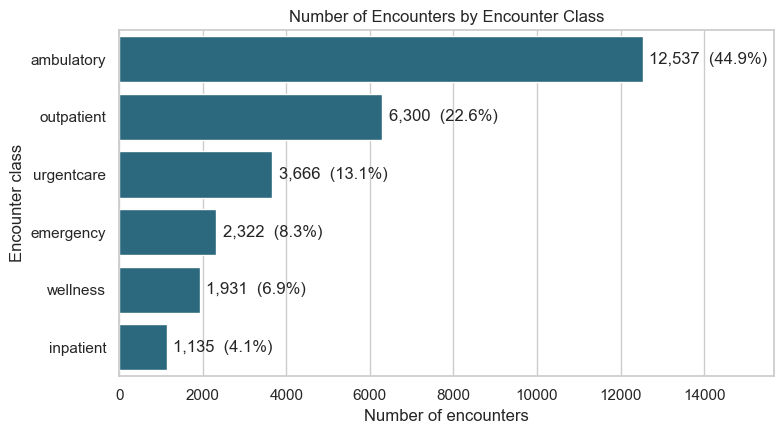

In [16]:
counts = enc["ENCOUNTERCLASS"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=counts.values, y=counts.index, color=BLUE, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(v + 150, i, f"{v:,}  ({v / len(enc):.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title("Number of Encounters by Encounter Class")
ax.set_xlabel("Number of encounters"); ax.set_ylabel("Encounter class")
save_fig("01_encounters_by_class.png")
RESULTS["class_counts"] = {k: int(v) for k, v in counts.items()}

**Shows:** ambulatory visits are the largest group (about 45% of records); inpatient stays the smallest. **Cannot show:** how much each class costs or how long each takes, only how often each is recorded. The groups are very unequal in size, which matters for the tests later.

## 5.3 Visualisation 2 – Encounter volume by year

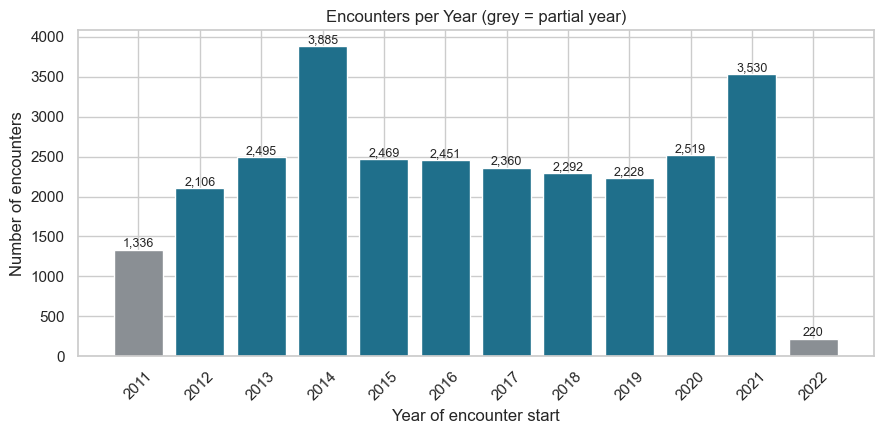

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cols = [GREY if y in (by_year.index.min(), by_year.index.max()) else BLUE for y in by_year.index]
ax.bar(by_year.index.astype(str), by_year.values, color=cols)
for x, v in zip(range(len(by_year)), by_year.values): ax.text(x, v + 40, f"{v:,}", ha="center", fontsize=9)
ax.set_title("Encounters per Year (grey = partial year)")
ax.set_xlabel("Year of encounter start"); ax.set_ylabel("Number of encounters"); ax.tick_params(axis="x", rotation=45)
save_fig("02_encounters_by_year.png")
peak = by_year.drop([by_year.index.min(), by_year.index.max()]).sort_values(ascending=False).head(2)
RESULTS["peak_years"] = {int(k): int(v) for k, v in peak.items()}; RESULTS["by_year"] = {int(k): int(v) for k, v in by_year.items()}

**Shows:** volumes are not steady: they peak in two years (2014 and 2021) and are lower in between. The grey bars are incomplete years (the data starts on 2 January 2011 and ends on 5 February 2022), so they must not be compared with full years. **Cannot show:** *why* volumes changed (growth, policy, how the records were generated); the pattern could even come from how the data was produced.

## 5.4 Visualisation 3 – How are total claim costs distributed?

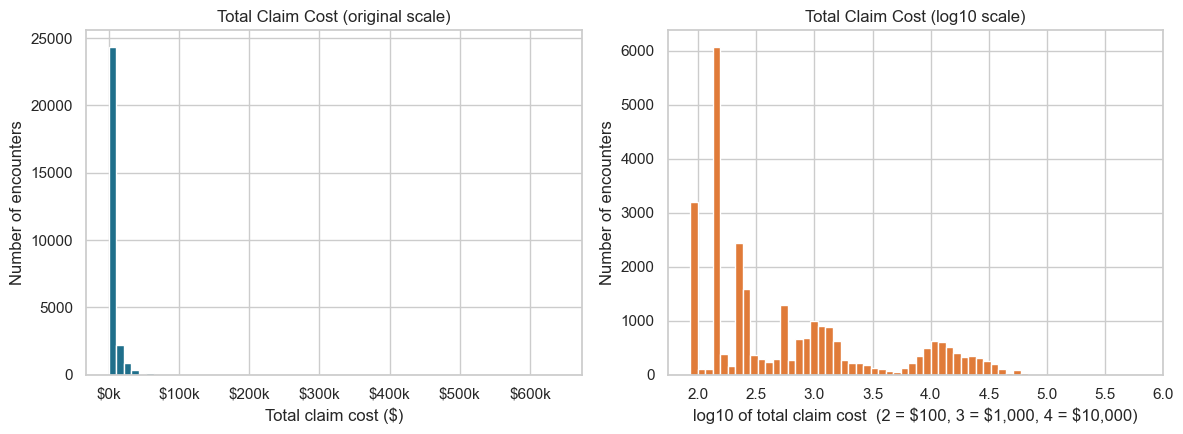

Skewness of total claim cost: 16.3 | the most expensive 1% of encounters account for 14.5% of all cost; the top 10% for 66.6%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(enc["TOTAL_CLAIM_COST"], bins=60, color=BLUE)
axes[0].set_title("Total Claim Cost (original scale)"); axes[0].set_xlabel("Total claim cost ($)"); axes[0].set_ylabel("Number of encounters")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"${v / 1000:,.0f}k"))
axes[1].hist(enc["log10_cost"].dropna(), bins=60, color=ORANGE)
axes[1].set_title("Total Claim Cost (log10 scale)"); axes[1].set_xlabel("log10 of total claim cost  (2 = $100, 3 = $1,000, 4 = $10,000)"); axes[1].set_ylabel("Number of encounters")
save_fig("03_cost_distribution.png")
top = enc["TOTAL_CLAIM_COST"].sort_values(ascending=False)
top1, top10 = top.head(int(len(top) * .01)).sum() / top.sum(), top.head(int(len(top) * .10)).sum() / top.sum()
print(f"Skewness of total claim cost: {enc['TOTAL_CLAIM_COST'].skew():.1f} | the most expensive 1% of encounters account for {top1:.1%} of all cost; the top 10% for {top10:.1%}")
RESULTS.update({"cost_skew": float(enc["TOTAL_CLAIM_COST"].skew()), "top1_share": float(top1 * 100), "top10_share": float(top10 * 100)})

**Shows:** on the original scale almost everything is squashed against zero, with a very long tail of expensive encounters. The log chart reveals several separate peaks, which suggests different types of encounter with very different typical costs. **Cannot show:** that the cheapest or dearest encounters are "better" or "worse" (it is cost only). This skew is why **rank-based tests and medians** are used instead of t-tests and averages.

## 5.5 Visualisation 4 – Cost by encounter class (box plot)

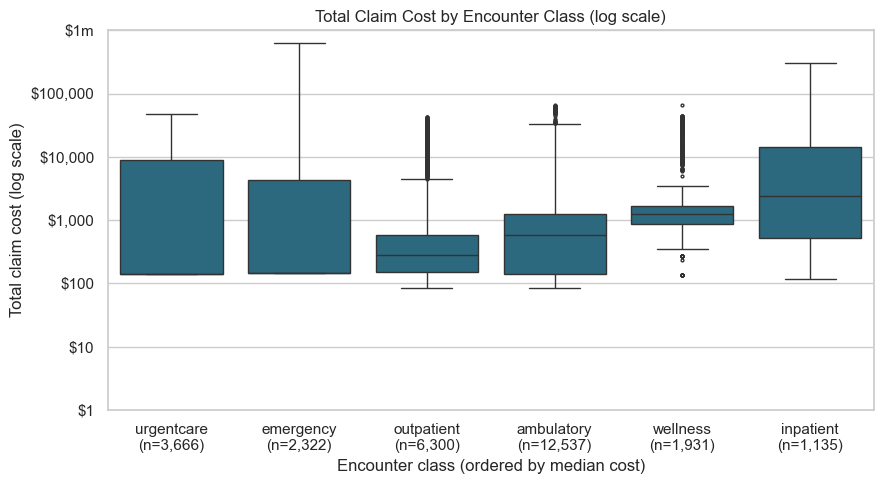

In [19]:
order_by_median = summary["median_cost"].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=enc.dropna(subset=["log10_cost"]), x="ENCOUNTERCLASS", y="log10_cost", order=order_by_median, color=BLUE, fliersize=2, ax=ax)
ax.set_yticks([0, 1, 2, 3, 4, 5, 6]); ax.set_yticklabels(["$1", "$10", "$100", "$1,000", "$10,000", "$100,000", "$1m"])
ax.set_xticklabels([f"{c}\n(n={summary.loc[c, 'encounters']:,})" for c in order_by_median])
ax.set_title("Total Claim Cost by Encounter Class (log scale)"); ax.set_xlabel("Encounter class (ordered by median cost)"); ax.set_ylabel("Total claim cost (log scale)")
save_fig("04_cost_by_class_boxplot.png")

**Shows:** the classes sit at very different cost levels, and the boxes barely overlap for the extremes, while some classes have wide spreads. **Cannot show:** exact differences (log scale compresses them) or *why* a class costs more (procedures, patient condition and payer are all mixed in).

## 5.6 Visualisation 5 – Is duration related to cost?

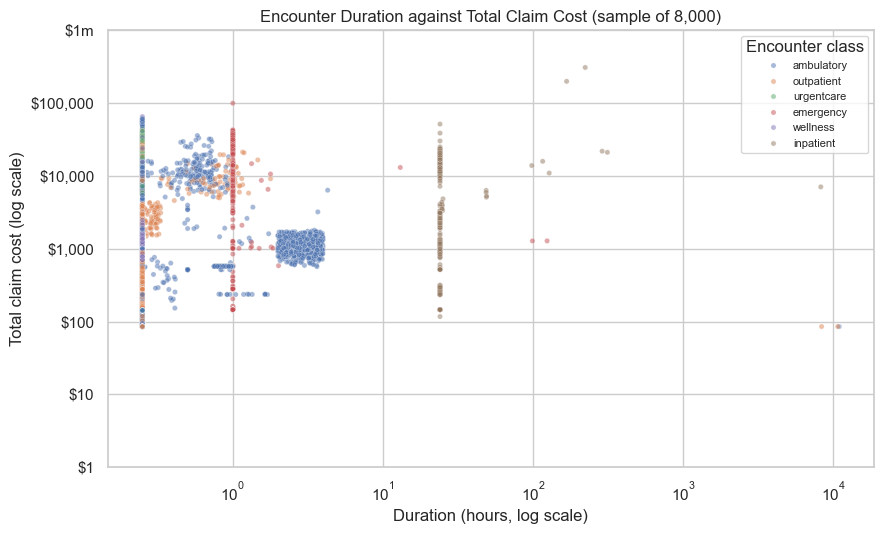

In [25]:
valid = enc.dropna(subset=["log10_cost"])
sample = valid.sample(8000, random_state=SEED)                                    # 8,000 points keep the chart readable
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=sample, x="duration_hours", y="log10_cost", hue="ENCOUNTERCLASS", hue_order=class_order, s=14, alpha=0.5, ax=ax)
ax.set_xscale("log")
ax.set_yticks([0, 1, 2, 3, 4, 5, 6]); ax.set_yticklabels(["$1", "$10", "$100", "$1,000", "$10,000", "$100,000", "$1m"])
ax.set_title("Encounter Duration against Total Claim Cost (sample of 8,000)"); ax.set_xlabel("Duration (hours, log scale)"); ax.set_ylabel("Total claim cost (log scale)"); ax.legend(title="Encounter class", fontsize=8)
save_fig("05_duration_vs_cost.png")

**Shows:** the vertical stripes are classes with a **fixed duration** (all their encounters last the same time), so those classes spread across all costs at one duration value. Where duration varies (ambulatory, outpatient) cost tends to rise with it. **Cannot show:** that longer care *causes* higher cost: longer encounters may simply involve more procedures.

## 5.7 Visualisation 6 – Recorded payer coverage

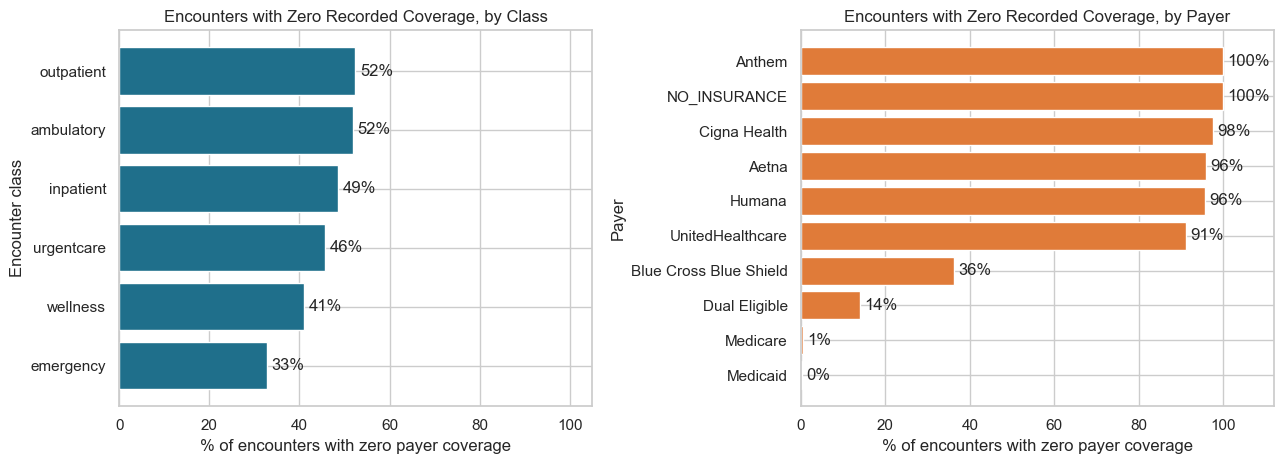

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
zc = summary["zero_coverage_share"].sort_values() * 100
axes[0].barh(zc.index, zc.values, color=BLUE)
for i, v in enumerate(zc.values): axes[0].text(v + 1, i, f"{v:.0f}%", va="center")
axes[0].set_xlim(0, 105); axes[0].set_title("Encounters with Zero Recorded Coverage, by Class"); axes[0].set_xlabel("% of encounters with zero payer coverage"); axes[0].set_ylabel("Encounter class")
pz = payer_tbl["zero_coverage_share"].sort_values() * 100
axes[1].barh(pz.index, pz.values, color=ORANGE)
for i, v in enumerate(pz.values): axes[1].text(v + 1, i, f"{v:.0f}%", va="center")
axes[1].set_xlim(0, 112); axes[1].set_title("Encounters with Zero Recorded Coverage, by Payer"); axes[1].set_xlabel("% of encounters with zero payer coverage"); axes[1].set_ylabel("Payer")
save_fig("06_zero_coverage.png")

**Shows:** zero coverage varies by class, but varies far more by **payer**: some private payers show zero coverage on almost every encounter, which is unlikely to reflect real payment. **Cannot show:** who actually paid. Zero coverage in this dataset is ambiguous and must not be read as "uninsured".

---
# 6. Hypothesis testing

Two hypotheses are tested because they directly address the research question.

- **H1:** Do recorded total claim costs differ across encounter classes?
- **H2:** Is encounter duration associated with recorded total claim cost?

The cost data is strongly right-skewed. Therefore, rank-based methods are used rather than methods that assume normally distributed costs. Statistical significance is interpreted alongside the size and practical meaning of the observed differences.


## 6.1 H1 – Do total claim costs differ across encounter classes?

- **Null hypothesis (H0):** Total claim costs have the same distribution across encounter classes.
- **Alternative hypothesis (H1):** At least one encounter class has a different cost distribution.
- **Method:** Kruskal–Wallis test. This is a rank-based test suitable for comparing a numeric outcome across more than two independent groups when the data is not normally distributed.

The test assumes independent observations. This assumption may be imperfect because the same patient can have multiple encounters; this is noted as a limitation.


In [22]:
groups = [enc.loc[enc["ENCOUNTERCLASS"] == c, "TOTAL_CLAIM_COST"].dropna()
          for c in class_order]

group_check = pd.DataFrame({
    "encounters": [len(g) for g in groups],
    "median_cost": [g.median() for g in groups],
    "mean_cost": [g.mean() for g in groups]
}, index=class_order)

display(group_check.round(2))
print("The median and mean are quite different in some groups, indicating skewed costs.")


,encounters,median_cost,mean_cost
ambulatory,12537,573.98,2894.11
outpatient,6300,278.58,2237.30
urgentcare,3666,142.58,6369.16
emergency,2322,146.18,4629.65
wellness,1931,1231.44,4260.71
inpatient,1135,2355.59,7761.35


The median and mean are quite different in some groups, indicating skewed costs.


In [23]:
h1_stat, h1_p = stats.kruskal(*groups)

print(f"Kruskal–Wallis statistic: {h1_stat:.2f}")
print(f"p-value: {h1_p:.4g}")

if h1_p < 0.05:
    print("Decision: Reject H0. There is evidence that claim-cost distributions differ across encounter classes.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of a difference across encounter classes.")


Kruskal–Wallis statistic: 2025.19
p-value: 0
Decision: Reject H0. There is evidence that claim-cost distributions differ across encounter classes.


### H1 interpretation

A statistically significant result indicates that at least one encounter class has a different distribution of recorded claim costs. The test does not identify which specific pairs of classes differ. Use the group medians and box plot above to describe the observed pattern.

A small p-value does not by itself mean the difference is important in practice. Also, the test compares distributions; interpreting it strictly as a comparison of medians requires the groups to have similarly shaped distributions.


## 6.2 H2 – Is encounter duration associated with total claim cost?

- **Null hypothesis (H0):** There is no monotonic association between encounter duration and total claim cost (Spearman correlation = 0).
- **Alternative hypothesis (H1):** There is a monotonic association between encounter duration and total claim cost.
- **Method:** Spearman rank correlation. It measures whether higher duration values tend to occur with higher or lower cost values and does not require a straight-line relationship.

Some encounter classes have fixed durations. This limits how much the overall correlation can tell us about the relationship within those classes.


In [29]:
rho, h2_p = stats.spearmanr(enc["duration_hours"], enc["TOTAL_CLAIM_COST"])

print(f"Spearman correlation: {rho:.3f}")
print(f"p-value: {h2_p:.4g}")

if h2_p < 0.05:
    print("Decision: Reject H0. There is evidence of an association between duration and claim cost.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of an association.")


Spearman correlation: 0.338
p-value: 0
Decision: Reject H0. There is evidence of an association between duration and claim cost.


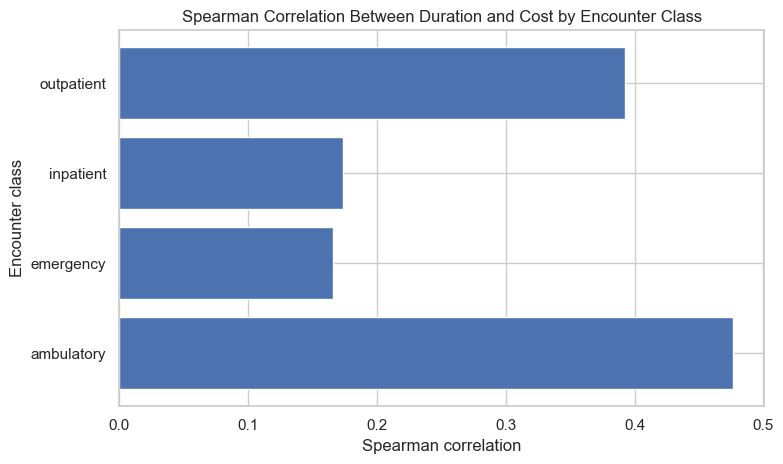

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.8))
class_corr = enc.groupby("ENCOUNTERCLASS").apply(
    lambda g: g["duration_hours"].corr(g["TOTAL_CLAIM_COST"], method="spearman")
)
class_corr = class_corr.dropna()
ax.barh(class_corr.index, class_corr.values)
ax.set_title("Spearman Correlation Between Duration and Cost by Encounter Class")
ax.set_xlabel("Spearman correlation")
ax.set_ylabel("Encounter class")
save_fig("06_duration_cost_correlation_by_class.png")


### H2 interpretation

Spearman's correlation ranges from -1 to +1. A positive value means longer encounters tend to be associated with higher costs; a negative value means longer encounters tend to be associated with lower costs. Values close to zero indicate a weak monotonic relationship.

This is an association, not evidence that longer duration causes higher costs. Other factors, such as procedures or the type of care provided, may influence both.


---
# 7. Limitations

- **Repeated encounters:** A patient may appear more than once, so observations may not be fully independent. This can affect statistical test results.
- **Missing information:** Some reason fields contain missing values. They were not needed for this research question and were left unchanged.
- **Skewed costs:** A small number of expensive encounters can strongly affect averages. Medians are therefore reported alongside means.
- **Extreme durations:** Some records have unusually long durations. They are retained but should be interpreted cautiously.
- **Fixed durations:** Some encounter classes have the same recorded duration, limiting the usefulness of duration comparisons within those groups.
- **Confounding:** Procedures, payer and patient characteristics may also affect claim costs. The analysis does not isolate their individual effects.
- **Payer coverage:** Zero recorded coverage does not necessarily mean a patient was uninsured; some records have a named payer but zero coverage.
- **Generalisability:** The dataset represents one organisation and a defined historical period. Findings should not automatically be generalised to other hospitals.

**Association versus causation:** The analysis identifies patterns in the supplied data. It does not establish that encounter class or duration causes a change in claim cost.


---
# 8. Basic validation

Check that the analysis dataset has the expected number of records, that encounter IDs are unique, and that the key analysis fields are available.


In [31]:
checks = {
    "Expected number of encounter records": len(enc) == 27891,
    "Encounter IDs are unique": enc["Id"].is_unique,
    "No missing values in analysis fields": enc[
        ["ENCOUNTERCLASS", "TOTAL_CLAIM_COST", "START", "STOP", "duration_hours"]
    ].notna().all().all()
}

for check, passed in checks.items():
    print(f"{check}: {'PASS' if passed else 'CHECK'}")


Expected number of encounter records: PASS
Encounter IDs are unique: PASS
No missing values in analysis fields: PASS


---
# 9. Findings and recommendations

## Key findings

1. Claim costs vary across encounter classes. The Kruskal–Wallis test indicates whether the observed differences are statistically significant.
2. The median is a useful measure of typical cost because the cost distribution is strongly right-skewed.
3. The Spearman test indicates whether encounter duration and claim cost are associated. This relationship should not be interpreted as causal.
4. Recorded payer coverage contains ambiguous zero values and should be interpreted cautiously.

## Recommendations

1. Review encounter classes with higher typical claim costs to understand what services and procedures contribute to the difference.
2. Report median costs alongside averages so that unusually expensive encounters do not distort the picture of typical costs.
3. Investigate high-cost encounters separately, using additional information about procedures and patient characteristics where appropriate.
4. Clarify the meaning of zero payer coverage with the data owner before using it to assess insurance coverage.

These recommendations are based on patterns in the supplied dataset. Further information is needed before operational changes are made.


---
# 10. How to reproduce this analysis

1. Place this notebook in your project folder.
2. Create a subfolder named `data`.
3. Place the supplied CSV files in `data/`: `encounters.csv`, `procedures.csv`, `payers.csv`, `organizations.csv`, `patients.csv`, and `data_dictionary.csv`.
4. Install the required libraries if they are not already installed: `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scipy`.
5. Restart the notebook kernel and run all cells from top to bottom.

The notebook saves visualisations and summary tables in the `outputs` folder and the data-quality summary in the `reports` folder.

**Privacy:** Patient names and addresses are not loaded into the analysis. Do not publish identifiable patient information.
